# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATSolveCoP_long/545.csv',
        ),
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'])

In [6]:
strategies = data.strategy.unique()
strategies

array(['FirstAction', 'LeanCopCut', 'SATSolveLiteral',
       'SATSolveLearnInitial', 'SATSolveLearnControl'], dtype=object)

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [9]:
data.problem.str[:3].unique()

array(['AGT', 'ALG', 'ANA', 'BIO', 'BOO', 'CAT', 'COL', 'COM', 'CSR',
       'FLD', 'GEO', 'GRA', 'GRP', 'HEN', 'HWV', 'KLE', 'KRS', 'LAT',
       'LCL', 'LDA', 'MGT', 'NLP', 'NUM', 'PLA', 'PRO', 'PUZ', 'REL',
       'RNG', 'SCT', 'SET', 'SEU', 'SWB', 'SWC', 'SWV', 'SWW', 'SYN',
       'TOP'], dtype=object)

# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error
80,ALG397-1.p,FirstAction,solved,True,1009.0,7975.0,NaN,NaN
81,ALG397-1.p,LeanCopCut,solved,True,1009.0,7826.0,NaN,NaN
82,ALG397-1.p,SATSolveLiteral,solved,True,0.0,0.0,NaN,NaN
83,ALG397-1.p,SATSolveLearnInitial,solved,True,0.0,0.0,NaN,NaN
84,ALG397-1.p,SATSolveLearnControl,solved,True,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...
2430,SYN729-1.p,FirstAction,solved,True,444.0,120.0,Theorem,NaN
2431,SYN729-1.p,LeanCopCut,solved,True,444.0,119.0,Theorem,NaN
2432,SYN729-1.p,SATSolveLiteral,solved,True,113.0,36.0,"Theorem (SAT); literal=choices:64,forward:189,...",NaN
2433,SYN729-1.p,SATSolveLearnInitial,solved,True,219.0,103.0,"Theorem (SAT); literal=choices:126,forward:382...",NaN


In [12]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction             40
LeanCopCut              48
SATSolveLearnControl    72
SATSolveLearnInitial    49
SATSolveLiteral         60
dtype: int64

# Results

<Axes: xlabel='strategy'>

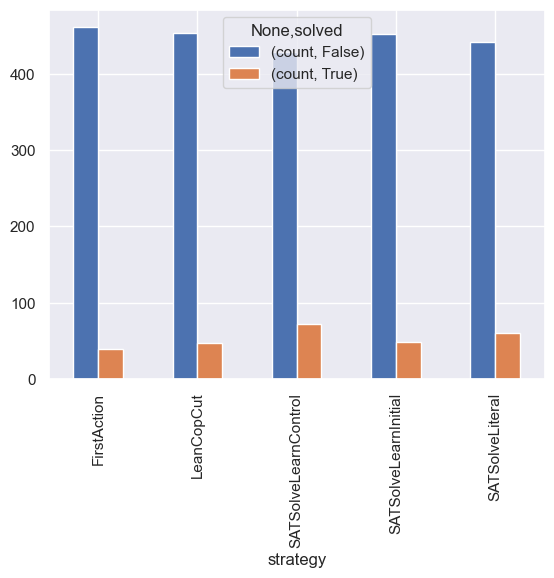

In [13]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

In [14]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [15]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,FirstAction,LeanCopCut,SATSolveLearnControl,SATSolveLearnInitial,SATSolveLiteral
strategy_left,,,,,
FirstAction,501,501,501,501,501
LeanCopCut,501,501,501,501,501
SATSolveLearnControl,501,501,501,501,501
SATSolveLearnInitial,501,501,501,501,501
SATSolveLiteral,501,501,501,501,501


Text(0.5, 1.0, 'Winners and losers of different SAT policies. Total of 501 problems.')

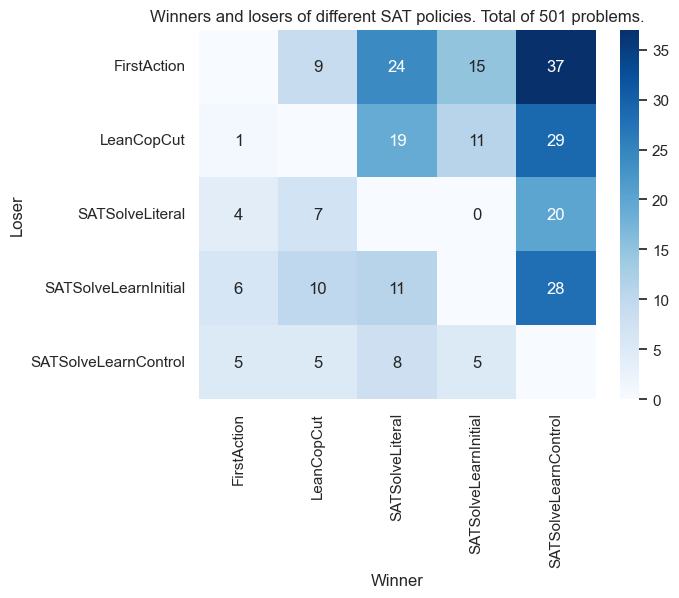

In [16]:
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = merged.strategy_left.unique(), columns = merged.strategy_left.unique(), fill_value = 0)
)

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided').
    rename(columns = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided')
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'Blues',
)
pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot.png', bbox_inches = 'tight')

Text(0.5, 1.0, 'Winners and losers of different SAT policies. Total of 274 problems.')

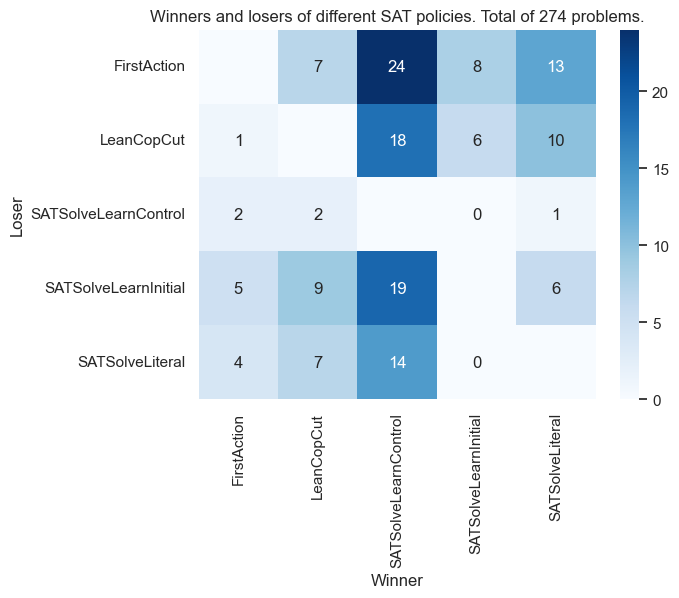

In [17]:
subset = merged[merged.problem.str.contains(r'\+')]

results = (
    subset
    [~subset.solved_left & subset.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
)

cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided').
    rename(columns = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided')
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(plot.index.size, dtype = bool), ''),
    fmt = 's',
    cmap = 'Blues',
)
pyplot.title(f'Winners and losers of different SAT policies. Total of {subset.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot.png', bbox_inches = 'tight')

# Analysis

## Hard Problems

In [18]:
literal = data[data.strategy == 'SATSolveLiteral'].loc[lambda x: x.solved]

In [19]:
literal[literal.problem.str.startswith('SYN')].sort_values('steps', ascending = False).head(40)

,problem,strategy,status,solved,steps,time_ms,info,error
2307,SYN209-1.p,SATSolveLiteral,solved,True,26905.0,55014.0,"Theorem (SAT); literal=choices:14289,forward:3...",NaN
2397,SYN625-1.p,SATSolveLiteral,solved,True,18502.0,41801.0,"Theorem (SAT); literal=choices:10997,forward:5...",NaN
2292,SYN154-1.p,SATSolveLiteral,solved,True,18150.0,37034.0,"Theorem (SAT); literal=choices:9598,forward:21...",NaN
2297,SYN158-1.p,SATSolveLiteral,solved,True,17984.0,32632.0,Theorem (SAT); score=1.0; literal=choices:9526...,NaN
2417,SYN704-1.p,SATSolveLiteral,solved,True,15570.0,11618.0,"Theorem (SAT); literal=choices:9613,forward:69...",NaN
2422,SYN707-1.p,SATSolveLiteral,solved,True,12489.0,35353.0,"Theorem (SAT); literal=choices:7333,forward:67...",NaN
2317,SYN260-1.p,SATSolveLiteral,solved,True,9156.0,15506.0,"Theorem (SAT); literal=choices:4819,forward:11...",NaN
2312,SYN211-1.p,SATSolveLiteral,solved,True,9111.0,15698.0,"Theorem (SAT); literal=choices:4800,forward:11...",NaN
2387,SYN586-1.p,SATSolveLiteral,solved,True,4557.0,4376.0,"Theorem (SAT); literal=choices:2684,forward:11...",NaN
2392,SYN594-1.p,SATSolveLiteral,solved,True,609.0,717.0,"Theorem (SAT); literal=choices:353,forward:218...",NaN


In [20]:
data[data.problem == 'SYN209-1.p']

,problem,strategy,status,solved,steps,time_ms,info,error
2305,SYN209-1.p,FirstAction,timeout,False,42135.0,60001.0,NaN,NaN
2306,SYN209-1.p,LeanCopCut,timeout,False,42642.0,60000.0,NaN,NaN
2307,SYN209-1.p,SATSolveLiteral,solved,True,26905.0,55014.0,"Theorem (SAT); literal=choices:14289,forward:3...",NaN
2308,SYN209-1.p,SATSolveLearnInitial,timeout,False,17783.0,60004.0,"literal=choices:9418,forward:216282,unique:933...",NaN
2309,SYN209-1.p,SATSolveLearnControl,solved,True,1260.0,3777.0,"Theorem (SAT); literal=choices:1126,forward:57...",NaN
